# 08 - First steps in Python

**MATH 331 - Differential Equations.** Lecture plan: Session 2 (Python and Jupyter; plot functions and solve a linear system).

This is the place to start if you have never programmed. You already know the mathematics: it
is the diagnostic exam of Session 1. Here the computer **checks** the answers you found by hand.

**References**
* The appendix of Lecture 1 (worked solutions of the diagnostic questions) and the review videos
  R01-R11.
* J. Lebl, *Notes on Diffy Qs*: Section 0.2 (what a differential equation is), Example 2.3.3
  (the three-by-three system of Section 4 below).

**What you will learn**
1. How to run a cell, change it, and read an error message.
2. Python as a calculator; how to plot a function; how to solve a linear system.
3. How SymPy differentiates, integrates and solves equations exactly.
4. Why a computer computes **approximately**, and why this matters in this course.

Two rules for the whole course: *Python checks and shows what you do by hand*; and *an answer
of the computer is trusted only after a check*.

## 1. A notebook in two minutes

A notebook is made of **cells**. Some contain text (like this one), some contain Python code.

* Click on a code cell and press **Shift+Enter**: the cell runs and its result appears below it.
* Cells run **in the order you run them**. If something looks wrong, run the cells again from the
  top (menu *Run > Run All Cells*).
* You cannot break anything: this notebook can always be downloaded again.

**Run the next cell now.** It loads the tools used in every notebook of the course. The first
time, on the course site, it can take up to a minute. (If you have already run everything with
the `>>` button, run it again: no harm.)

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# of the course (here: check, which compares your answer with the expected one).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import Math, display                 # noqa: F401  (not used in every notebook)
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


The names loaded above are used all the time: `np` (NumPy: numbers and arrays), `sp` (SymPy:
exact, symbolic mathematics), `plt` (plots).

Now **change** a cell. Run the next one; then replace `5` with another number and run it again.

In [2]:
SECONDS_PER_MINUTE = 60

minutes = 5            # change this number, then press Shift+Enter again
print("In", minutes, "minutes there are", minutes * SECONDS_PER_MINUTE, "seconds")

In 5 minutes there are 300 seconds


The text after `#` is a **comment**: Python ignores it; it is there for you.

**What to do when you see red.** Make a mistake on purpose: in the cell above, change the first
`minutes` after `print(` (the one without quotes) to `minuts`, and run the cell. A red message appears. Read its **last
line**:

```
NameError: name 'minuts' is not defined
```

It says what went wrong, in plain English; the arrow above it shows the line. In this course a
line that starts with *Hint (MATH 331)*, just above or below the red box, often says what to
do. Correct the word and run the cell again. Errors are normal: everybody makes dozens of them
a day. The messages you will meet most often are explained in notebook 00, and by `ol.guide("errors")`.

## 2. Python as a calculator

The usual rules of arithmetic hold. Three things differ from paper:

| On paper | In Python | |
|---|---|---|
| $2^{10}$ | `2 ** 10` | two stars; `^` means something else |
| $3x$ | `3 * x` | the product is always written |
| $3.5$ | `3.5` | a point, never a comma |

In [3]:
print(2 + 3 * 4)              # the product first, as on paper
print(2 ** 10)                # a power
print(7 / 2, 7 // 2, 7 % 2)   # division, its whole part, its remainder

14
1024
3.5 3 1


Functions and constants come from NumPy: `np.exp`, `np.log` (the natural logarithm), `np.sqrt`,
`np.sin`, `np.cos`, `np.pi`.

A **variable** is a name for a value. With names, a computation reads like the mathematics. Here
is the coffee of Session 1: it starts at 90 degrees, is at 80 degrees after 5 minutes, in a room
at 20 degrees. Newton's law of cooling gives

$$
T(t) = T_{room} + (T_{start} - T_{room})\,e^{-kt} .
$$

Solving for $k$ with the measurement, and then for the time at which $T = 60$ degrees:

In [4]:
T_start = 90.0     # degrees Celsius, at t = 0
T_later = 80.0     # degrees Celsius, at t = t_later
t_later = 5.0      # minutes
T_room = 20.0      # degrees Celsius
T_drink = 60.0     # degrees Celsius: drinkable

k = np.log((T_start - T_room) / (T_later - T_room)) / t_later
t_drink = np.log((T_start - T_room) / (T_drink - T_room)) / k

print(f"k = {k:.4f} per minute")
print(f"the coffee is drinkable after {t_drink:.2f} minutes")

k = 0.0308 per minute
the coffee is drinkable after 18.15 minutes


`f"... {k:.4f} ..."` writes the value of `k` with four decimals inside a sentence.

*Check by hand:* $k = \tfrac{1}{5}\ln\tfrac{7}{6}$ and $t = \tfrac{1}{k}\ln\tfrac{7}{4}$, the
numbers on the slides of Session 1.

## 3. Plot a function

To plot $f(x) = x\,e^{-x}$ (Question 11 of the diagnostic exam), the computer does what you would
do on paper: it takes many values of $x$, computes $f$ at each of them, and joins the points.

* `np.linspace(a, b, n)` gives `n` equally spaced numbers from `a` to `b`: an **array**.
* A formula applied to an array is applied to every number in it.

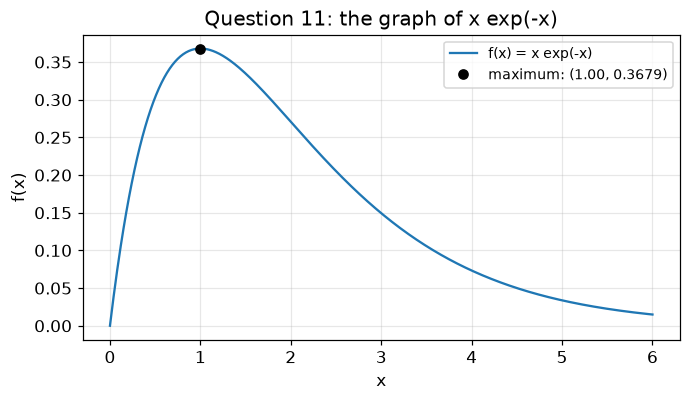

largest value on the grid: f(1.00) = 0.3679;  1/e = 0.3679


In [5]:
def f(x):
    return x * np.exp(-x)


X_MIN, X_MAX, N_POINTS = 0.0, 6.0, 601       # step 0.01
FIGURE_SIZE = (7.0, 3.6)

x_values = np.linspace(X_MIN, X_MAX, N_POINTS)
y_values = f(x_values)

i_max = np.argmax(y_values)                  # position of the largest value
x_max, y_max = x_values[i_max], y_values[i_max]

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ax.plot(x_values, y_values, label="f(x) = x exp(-x)")
ax.plot(x_max, y_max, "o", color="black", label=f"maximum: ({x_max:.2f}, {y_max:.4f})")
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.set_title("Question 11: the graph of x exp(-x)")
ax.legend()
plt.show()

print(f"largest value on the grid: f({x_max:.2f}) = {y_max:.4f};  1/e = {np.exp(-1):.4f}")
assert np.isclose(x_max, 1.0) and np.isclose(y_max, np.exp(-1))

*The plot shows* a curve that starts at 0, rises to its maximum $1/e \approx 0.368$ at $x = 1$
(black dot), then decreases towards 0 without reaching it.

By hand: $f'(x) = (1 - x)e^{-x}$ vanishes at $x = 1$ (video R11). The computer found the same
point **by looking at 601 values**: it did not differentiate anything. The last line, `assert`,
stops the notebook if the two answers disagree: this is how every notebook of the course checks
itself.

## 4. Solve a linear system

Question 8 of the diagnostic exam:

$$
\begin{aligned} 2x + y &= 5 \\ x - y &= 1 \end{aligned}
\qquad\Longleftrightarrow\qquad
\begin{pmatrix} 2 & 1 \\ 1 & -1 \end{pmatrix}\begin{pmatrix} x \\ y \end{pmatrix}
= \begin{pmatrix} 5 \\ 1 \end{pmatrix} .
$$

The computer needs the matrix of the coefficients, `A`, and the right-hand side, `b`.

In [6]:
A = np.array([[2.0, 1.0],
              [1.0, -1.0]])
b = np.array([5.0, 1.0])

solution = np.linalg.solve(A, b)
print("x, y =", solution)
print("check, A times the solution:", A @ solution, " (it must be b)")
assert np.allclose(A @ solution, b)

x, y = [2. 1.]
check, A times the solution: [5. 1.]  (it must be b)


`A @ solution` is the product of the matrix and the vector: putting the solution back into the
equations is the check you would do by hand (video R08).

**Where this is used in the course.** Initial conditions always lead to a linear system. Lebl,
Example 2.3.3: the solutions of $y''' - 3y'' - y' + 3y = 0$ are
$y = C_1 e^{-x} + C_2 e^{x} + C_3 e^{3x}$, and the conditions $y(0) = 1$, $y'(0) = 2$,
$y''(0) = 3$ give

$$
\begin{aligned} C_1 + C_2 + C_3 &= 1 \\ -C_1 + C_2 + 3C_3 &= 2 \\ C_1 + C_2 + 9C_3 &= 3 \end{aligned}
$$

Each row contains the exponents $-1, 1, 3$ raised to the power 0, 1, 2 (one more derivative,
one more power).

In [7]:
exponents = np.array([-1.0, 1.0, 3.0])
initial_values = np.array([1.0, 2.0, 3.0])               # y(0), y'(0), y''(0)

A3 = np.array([exponents ** order for order in range(exponents.size)])
C = np.linalg.solve(A3, initial_values)

print(A3)
print("C1, C2, C3 =", C)
assert np.allclose(C, [-1 / 4, 1, 1 / 4])                # Lebl, Example 2.3.3

[[ 1.  1.  1.]
 [-1.  1.  3.]
 [ 1.  1.  9.]]
C1, C2, C3 = [-0.25  1.    0.25]


## 5. The diagnostic exam, checked by the computer

NumPy works with numbers. **SymPy** works with symbols, as you do on paper: it differentiates,
integrates and solves **exactly**. First we say which letters are symbols.

In [8]:
x, y, r = sp.symbols("x y r")

derivative = sp.diff(x**2 * sp.exp(3 * x), x)            # Question 1
integral = sp.integrate(x * sp.exp(x**2), x)             # Question 2 (add the constant C yourself)

display(sp.factor(derivative))
display(integral)

assert sp.simplify(derivative - x * (3 * x + 2) * sp.exp(3 * x)) == 0
assert sp.simplify(integral - sp.exp(x**2) / 2) == 0

x*(3*x + 2)*exp(3*x)

exp(x**2)/2

Compare with your answers: $x(3x+2)e^{3x}$ (product and chain rule, video R01) and
$\tfrac12 e^{x^2} + C$ (substitution, video R02). SymPy does not write the constant of
integration: you must.

Equations (Questions 6 and 8) and Taylor series (Question 9):

In [9]:
roots_a = sp.solve(r**2 - 4 * r + 13, r)                 # Question 6(a)
roots_b = sp.solve(r**3 - r, r)                          # Question 6(b)
system = sp.solve([2 * x + y - 5, x - y - 1], [x, y])    # Question 8, exactly
SERIES_ORDER = 6
series_sin = sp.series(sp.sin(x), x, 0, SERIES_ORDER)    # Question 9(b)

print("r^2 - 4r + 13 = 0 :", roots_a)
print("r^3 - r = 0       :", roots_b)
print("2x + y = 5, x - y = 1 :", system)
print("sin x =", series_sin)

assert set(roots_a) == {2 - 3 * sp.I, 2 + 3 * sp.I}
assert system == {x: 2, y: 1}

r^2 - 4r + 13 = 0 : [2 - 3*I, 2 + 3*I]
r^3 - r = 0       : [-1, 0, 1]
2x + y = 5, x - y = 1 : {x: 2, y: 1}
sin x = x - x**3/6 + x**5/120 + O(x**6)


`I` is SymPy's imaginary unit; `O(x**6)` stands for "terms of degree 6 and higher". In an
equation, SymPy wants everything on the left: `r**2 - 4*r + 13` means $r^2 - 4r + 13 = 0$.

**Complex numbers** (Question 5) are built into Python, which writes `j` for $i$:

In [10]:
z = 3 + 4j
w = 1 - 2j

print("|z|        =", abs(z))
print("conjugate  =", z.conjugate())
print("z times w  =", z * w)
assert abs(z) == 5 and z * w == 11 - 2j

|z|        = 5.0
conjugate  = (3-4j)
z times w  = (11-2j)


## 6. Computers compute approximately

So far every check has passed. Now three surprises.

In [11]:
print(0.1 + 0.2)
print(0.1 + 0.2 == 0.3)                      # == asks: are they equal?
print(np.isclose(0.1 + 0.2, 0.3))            # equal up to rounding?

print(np.exp(1j * np.pi))                    # Question 5(c): Euler's formula says -1

0.30000000000000004
False
True
(-1+1.2246467991473532e-16j)


The computer stores numbers with about **16 significant digits**. The number 0.1 has infinitely
many digits in base 2 (as 1/3 has in base 10), so it is rounded; the same happens to $\pi$.
The errors are tiny, about $10^{-16}$, but they are there:

* never test decimal numbers with `==`: use `np.isclose`, as the `assert` lines above do;
* $e^{i\pi}$ comes out as $-1$ plus an imaginary part of size $10^{-16}$: read it as $-1$.

**When rounding matters.** The derivative of $x^2$ at $x = 1$ is 2. The computer can estimate it
as you did before learning the rules, with the slope of a secant line,

$$
\frac{f(x_0 + h) - f(x_0)}{h}, \qquad h \text{ small.}
$$

*Before running the next cell:* what do you expect as $h$ gets smaller and smaller?

In [12]:
def square(x):
    return x ** 2


x0 = 1.0
exact_slope = 2 * x0
STEPS = (1e-1, 1e-4, 1e-8, 1e-12, 1e-16)

for h in STEPS:
    slope = (square(x0 + h) - square(x0)) / h
    print(f"h = {h:.0e}   slope = {slope:.10f}   error = {abs(slope - exact_slope):.1e}")

h = 1e-01   slope = 2.1000000000   error = 1.0e-01
h = 1e-04   slope = 2.0001000000   error = 1.0e-04
h = 1e-08   slope = 1.9999999878   error = 1.2e-08
h = 1e-12   slope = 2.0001778012   error = 1.8e-04
h = 1e-16   slope = 0.0000000000   error = 2.0e+00


At first a smaller $h$ gives a better slope, as the mathematics says. Then the answer gets
**worse**, and for $h = 10^{-16}$ it is 0: the computer cannot tell $1 + 10^{-16}$ from 1, so the
numerator is zero. The picture for many values of $h$:

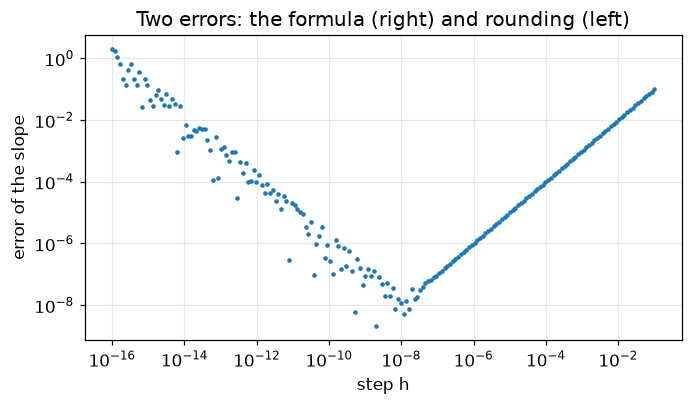

smallest error near h = 2e-09


In [13]:
H_EXPONENT_MIN, H_EXPONENT_MAX, H_COUNT = -16, -1, 200

h_values = np.logspace(H_EXPONENT_MIN, H_EXPONENT_MAX, H_COUNT)
errors = np.abs((square(x0 + h_values) - square(x0)) / h_values - exact_slope)
visible = errors > 0                                      # a logarithmic axis cannot show 0

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ax.loglog(h_values[visible], errors[visible], ".", markersize=4)
ax.set_xlabel("step h")
ax.set_ylabel("error of the slope")
ax.set_title("Two errors: the formula (right) and rounding (left)")
plt.show()

best = h_values[visible][np.argmin(errors[visible])]
print(f"smallest error near h = {best:.0e}")

*The plot shows*, on logarithmic axes, the error of the slope against $h$. From right to left
the error first decreases along a straight line (the error of the formula, proportional to $h$),
reaches its smallest value near $h = 10^{-8}$, then grows again in a scattered cloud (rounding).

This is the first lesson of numerical methods, and it comes back in the course (Euler's method,
notebook 04): **a numerical answer has an error; a smaller step helps only up to a point; so we
always compare with something we know.**

## 7. A first differential equation

The coffee obeys **Newton's law of cooling**: its temperature changes at a rate proportional to
the difference with the room,

$$
\frac{dT}{dt} = -k\,(T - T_{room}), \qquad T(0) = T_{start} .
$$

You will learn to solve it by hand in Week 2; the formula is the one of Section 2. The computer
can also solve it **numerically**, taking many small steps along the slope (Session 8).
`solve_ivp` ("solve the initial value problem") does that. We compare the two.

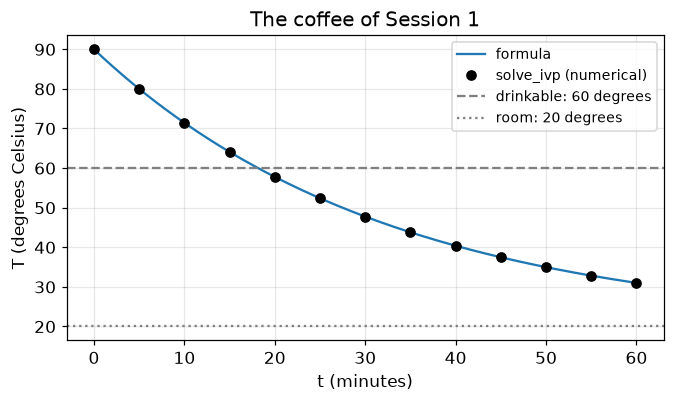

numerical temperature at t = 18.15 minutes: 60.0000 degrees


In [14]:
def cooling(t, T, k, T_room):
    return -k * (T - T_room)


def exact_temperature(t, k, T_room):
    return T_room + (T_start - T_room) * np.exp(-k * t)


T_END = 60.0                    # minutes
N_TIMES = 13                    # numerical values shown as dots, every 5 minutes
TOLERANCE = 1e-8

numerical = solve_ivp(cooling, (0.0, T_END), [T_start], args=(k, T_room),
                      dense_output=True, rtol=TOLERANCE, atol=TOLERANCE)

t_fine = np.linspace(0.0, T_END, N_POINTS)
t_dots = np.linspace(0.0, T_END, N_TIMES)

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ax.plot(t_fine, exact_temperature(t_fine, k, T_room), "-", label="formula")
ax.plot(t_dots, numerical.sol(t_dots)[0], "o", color="black", label="solve_ivp (numerical)")
ax.axhline(T_drink, linestyle="--", color="gray", label=f"drinkable: {T_drink:.0f} degrees")
ax.axhline(T_room, linestyle=":", color="gray", label=f"room: {T_room:.0f} degrees")
ax.set_xlabel("t (minutes)")
ax.set_ylabel("T (degrees Celsius)")
ax.set_title("The coffee of Session 1")
ax.legend()
plt.show()

T_numerical = numerical.sol(t_drink)[0]
print(f"numerical temperature at t = {t_drink:.2f} minutes: {T_numerical:.4f} degrees")
assert np.isclose(T_numerical, T_drink, atol=1e-4)

*The plot shows* the temperature falling from 90 degrees, quickly at first and then more and more
slowly, towards the room temperature (dotted line) without reaching it. The dots (numerical
solution) lie on the curve (formula); the curve crosses the dashed line, 60 degrees, after about
18 minutes.

**Sliders.** Answer *before* moving them:

1. If the room is colder, is the coffee drinkable sooner or later?
2. A thin paper cup has a larger $k$ than a thermos. Which curve falls faster?
3. Can the coffee ever become colder than the room?

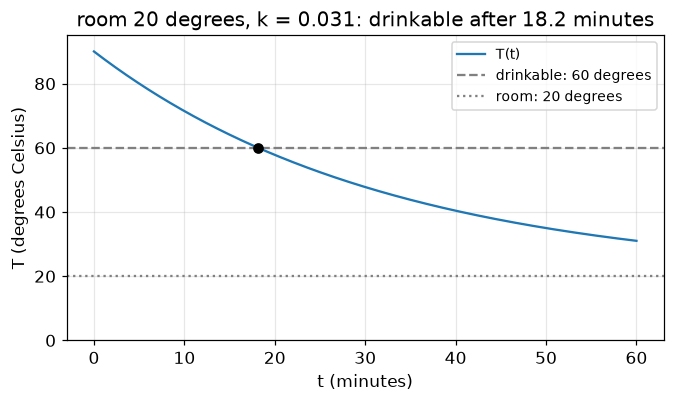

In [15]:
def plot_coffee(room=T_room, rate=k):
    t_reach = np.log((T_start - room) / (T_drink - room)) / rate
    fig, ax = plt.subplots(figsize=FIGURE_SIZE)
    ax.plot(t_fine, exact_temperature(t_fine, rate, room), "-", label="T(t)")
    ax.axhline(T_drink, linestyle="--", color="gray", label=f"drinkable: {T_drink:.0f} degrees")
    ax.axhline(room, linestyle=":", color="gray", label=f"room: {room:.0f} degrees")
    if t_reach <= T_END:
        ax.plot(t_reach, T_drink, "o", color="black")
    ax.set_ylim(0.0, T_start + 5.0)
    ax.set_xlabel("t (minutes)")
    ax.set_ylabel("T (degrees Celsius)")
    ax.set_title(f"room {room:.0f} degrees, k = {rate:.3f}: drinkable after {t_reach:.1f} minutes")
    ax.legend(loc="upper right")
    plt.show()


plot_coffee()                   # the picture without sliders: the data of Session 1

In [16]:
ROOM_RANGE = (0.0, 40.0, 1.0)           # minimum, maximum, step (degrees)
RATE_RANGE = (0.01, 0.10, 0.005)        # minimum, maximum, step (per minute)

interact(plot_coffee,
         room=FloatSlider(value=T_room, min=ROOM_RANGE[0], max=ROOM_RANGE[1], step=ROOM_RANGE[2],
                          description="room", continuous_update=False),
         rate=FloatSlider(value=round(k, 3), min=RATE_RANGE[0], max=RATE_RANGE[1], step=RATE_RANGE[2],
                          description="k", readout_format=".3f", continuous_update=False));

interactive(children=(FloatSlider(value=20.0, continuous_update=False, description='room', max=40.0, step=1.0)...

## 8. Exercises

Four kinds of exercise, the same in every notebook of the course. Final answers are at the end;
try first.

**Before you start:** run the whole notebook (the `>>` button at the top, then *Confirm Kernel Restart*; or the menu *Run > Run All Cells*), every time you open it: the exercises use what the
cells above define. In an answer cell change only the lines above the line that starts with `# ----`, then press Shift+Enter. If Python does not accept what you type, see "How to type
mathematics" in notebook 00, or click `+` at the top, type `ol.guide("typing")` in the new cell and press Shift+Enter.

### Exercise 1 - Predict (no computer)

Write down what you expect, **then** run the cell.

* `2 + 3 * 4`, `2 ** 3 ** 2`, `10 / 4`
* Is `np.exp(1j * np.pi)` exactly $-1$?

In [ ]:
print(2 + 3 * 4, 2 ** 3 ** 2, 10 / 4)
print(np.exp(1j * np.pi))

### Exercise 2 - By hand, then check

**(a)** Solve by hand: $4x - y = 2$, $\;x + 2y = 5$. Type your values in place of `None` and run
the cell: it tells you whether they are right.

In [18]:
my_x = None
my_y = None
# ---- your answers go above this line; the lines below check them (nothing to change) ----

A_exercise = np.array([[4.0, -1.0],
                       [1.0, 2.0]])
b_exercise = np.array([2.0, 5.0])

my_answer = None if my_x is None or my_y is None else [my_x, my_y]
ol.check("Exercise 2a", my_answer, np.linalg.solve(A_exercise, b_exercise));

Exercise 2a: no answer yet (replace None with your value)


**(b)** Differentiate $x^3 e^{-2x}$ by hand. Type your result in place of `None`, in Python
notation: for example `3 * x**2 * sp.exp(-2 * x)` (which is not the answer). Use `sp.exp`, not
`np.exp`: NumPy works with numbers, and with a symbol it answers with a red message about a
"loop of ufunc".

In [19]:
my_derivative = None
# ---- your answers go above this line; the lines below check them (nothing to change) ----

X_INTERVAL = (-1.0, 2.0)                # the two formulas are compared at a few points of this interval
ol.check_formula("Exercise 2b", my_derivative, sp.diff(x**3 * sp.exp(-2 * x), x), x, X_INTERVAL);

Exercise 2b: no answer yet (replace None with your formula)


### Exercise 3 - Fill in

Complete the function `g` so that it returns $x\,e^{-2x}$ (look at `f` in Section 3). The cell
after it finds the maximum on the grid and checks it against the value found by hand:
$x = \tfrac12$, $g = \tfrac{1}{2e}$.

In [20]:
def g(x):
    return None                 # replace None with the formula

In [21]:
DECAY = 2.0                     # the 2 of exp(-2x)

if g(1.0) is None:
    print("Exercise 3: complete g(x) first")
else:
    g_values = g(x_values)
    i_g = np.argmax(g_values)
    assert np.isclose(x_values[i_g], 1 / DECAY), "the maximum is not where it should be: check the formula"
    assert np.isclose(g_values[i_g], 1 / (DECAY * np.e)), "the largest value is not 1/(2e): check the formula"
    print(f"Exercise 3: correct, maximum at ({x_values[i_g]:.2f}, {g_values[i_g]:.4f})")

Exercise 3: complete g(x) first


### Exercise 4 - Explore

Plot $x^n e^{-x}$ for $n = 1, 2, 3, 4$ on one figure (use a longer interval than in Section 3).
Where are the maxima? State a conjecture, then prove it by hand.

*Hints.* A loop repeats a command: `for n in (1, 2, 3, 4):` followed by indented lines.
`ax.plot(x_values, x_values**n * np.exp(-x_values), label=f"n = {n}")` draws one curve.

In [22]:
# your code here

## 9. Answers

Final answers only; full solutions are given after the session.

<details>
<summary>Click to open (after trying)</summary>

1. `14`, `512` (powers are read from the right: $2^{(3^2)} = 2^9$), `2.5`. Not exactly: the result
   is $-1$ plus an imaginary part of about $1.2\cdot 10^{-16}$, a rounding error.
2. (a) $x = 1$, $y = 2$. (b) $x^2(3 - 2x)\,e^{-2x}$, typed as `x**2 * (3 - 2*x) * sp.exp(-2*x)`.
3. `return x * np.exp(-2 * x)`; maximum at $(0.5,\ 0.1839)$.
4. The maximum of $x^n e^{-x}$ is at $x = n$, because
   $\dfrac{d}{dx}\big(x^n e^{-x}\big) = x^{n-1}(n - x)\,e^{-x}$.

</details>

**Where to go next:** notebook 09 (slope fields and what a solution is, Session 3), or the
notebook of the current session in the list of the course site.